# Мини-BLIP на Flickr30k: ITC + ITM + LM, Recall@K, BLEU/CIDEr, CapFilt

**Собственная реализация** уменьшенной версии **BLIP** ([Li et al., ICML 2022](https://arxiv.org/abs/2201.12086)) на чистом PyTorch: визуальный энкодер (ViT) + текстовый энкодер-декодер с тремя лоссами. Архитектура и детали обучения (momentum-энкодеры, очередь, hard-negative для ITM, общие веса энкодера и декодера) следуют статье и репозиторию [salesforce/BLIP](https://github.com/salesforce/BLIP), который использован как образец; сам репозиторий не импортируется.

| лосс | что делает | где в коде |
|---|---|---|
| **ITC** (image-text contrastive) | выравнивает эмбеддинги картинки и текста; momentum-энкодеры + очередь + дистилляция | `MiniBLIP.forward` |
| **ITM** (image-text matching) | бинарная классификация «подпись подходит к картинке» с hard-negative из ITC; энкодер с cross-attention | `MiniBLIP.forward` |
| **LM** (language modeling) | авторегрессионная генерация подписи декодером с cross-attention | `MiniBLIP.forward` |

**Что в ноутбуке**
1. **Эксперимент 1.** Оценка модели *до* и *после* обучения на подвыборке Flickr30k: поиск по тексту (Recall@1/5/10, T→I и I→T; ITC и ITC+ITM-rerank) и генерация подписей (BLEU-1..4, CIDEr).
2. **Эксперимент 2. CapFilt.** Captioner генерирует синтетические подписи, filter (ITM) отсекает шум; сравнение 5 вариантов обучающих данных, анализ качества фильтра.
3. **Эксперимент 3.** Стратегии генерации: greedy, beam search, nucleus sampling.
4. **Медицинская адаптация (раздел 9).** Воспроизведение MedBLIP (2025) на ROCO: исходная BLIP zero-shot и три стратегии дообучения, дообучение нашей мини-BLIP (Flickr → ROCO), поиск по тексту, разбор ошибок (модальность, сторона, находки).

**Как запускать:** `Среда выполнения → Сменить тип → GPU (T4)`, затем «Выполнить все». Сначала лучше с `QUICK = True`.

**Сохранение.** Всё лежит на вашем Google Drive в `MyDrive/blip_mini/`: `checkpoints/` (обученные модели), `results/` (метрики, таблицы), `data/` (кэш данных). При повторном запуске **обученные модели загружаются, а не обучаются заново**, готовые метрики не пересчитываются. Чтобы переобучить, поставьте `FORCE_RETRAIN = True` или удалите нужный файл.

**Предобучение.** Текстовая часть, cross-attention и головы обучаются с нуля; ViT по умолчанию стартует с ImageNet-весов DeiT (`PRETRAINED_VIT`, это только инициализация). Предобученного на image-text парах BLIP здесь нет, поэтому «до» = модель в начальном состоянии.

## 0. Конфигурация
Все гиперпараметры в одной ячейке. **Для первого запуска поставьте `QUICK = True`** - весь пайплайн пройдёт на мини-данных за ~10 минут (проверка, что всё работает); потом `QUICK = False`.

In [ ]:
# ===================== КОНФИГУРАЦИЯ =====================
QUICK = False            # True = быстрый прогон-проверка (~10 мин): мини-данные, 1 эпоха. Результаты пишутся в отдельную папку.

MODEL = 'small'          # 'small': ViT-S/16 + текстовый трансформер 6 слоёв, dim 384  |  'base': ViT-B/16 + 12 слоёв, dim 768
PRETRAINED_VIT = True    # True: ViT стартует с ImageNet-весов DeiT (только как инициализация; код модели свой).
                         # Текстовая часть, cross-attention и все головы всегда обучаются с нуля.
IMAGE_SIZE = 224

# --- данные (Flickr30k, разбиение Karpathy) ---
N_TRAIN, N_VAL, N_TEST = 5000, 300, 1000    # число ИЗОБРАЖЕНИЙ (у каждого 5 подписей)
N_HUMAN    = 1000        # CapFilt: сколько train-изображений считаем «размеченными людьми» (5 подписей)
NOISE_RATE = 0.4         # CapFilt: доля «веб»-подписей, подменённых подписью чужой картинки

# --- обучение ---
BATCH_SIZE  = 64
QUEUE_SIZE  = 4096       # очередь momentum-признаков для ITC (кратна BATCH_SIZE)
ALPHA       = 0.4        # вес momentum-дистилляции (как в BLIP)
EPOCHS_MAIN    = 8      # основной эксперимент (вся подвыборка, 5 подписей/изобр.)
EPOCHS_CAPFILT = 5      # CapFilt-варианты (обучение с нуля на каждом наборе)
EPOCHS_FT_CF   = 3       # дообучение captioner / filter на «человеческих» данных
ITM_K          = 16      # сколько кандидатов ITC переранжирует ITM при оценке поиска
TAU            = 0.5     # порог ITM-фильтра (p(match) > TAU -> подпись остаётся)
SEED = 0
FORCE_RETRAIN = False    # True = игнорировать сохранённые чекпоинты и учить заново

if QUICK:
    N_TRAIN, N_VAL, N_TEST, N_HUMAN = 320, 32, 100, 96
    BATCH_SIZE, QUEUE_SIZE = 32, 512
    EPOCHS_MAIN = EPOCHS_CAPFILT = EPOCHS_FT_CF = 1
    ITM_K = 8

assert QUEUE_SIZE % BATCH_SIZE == 0

# learning rate: ViT (предобученный) и всё остальное (с нуля)
LR_BACKBONE, LR_NEW = (1e-4, 4e-4) if PRETRAINED_VIT else (4e-4, 4e-4)
SAVE_FP16 = (MODEL == 'base')            # base-чекпоинты хранить в fp16 (вдвое меньше места на Drive)

# --- пути: всё ценное лежит на Google Drive ---
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/blip_mini'
    LOCAL = '/content/work'
except ImportError:                       # запуск вне Colab
    ROOT = os.path.abspath('./blip_mini')       # распакованный архив с Drive: checkpoints/, results/, data/
    LOCAL = os.path.abspath('./blip_mini_local')
if QUICK:
    ROOT += '_quick'
CKPT_DIR = f'{ROOT}/checkpoints'   # обученные модели
RES_DIR  = f'{ROOT}/results'       # метрики (json), таблицы, графики
DATA_DIR = f'{ROOT}/data'          # кэш подвыборки Flickr30k (tar)
IMG_DIR  = f'{LOCAL}/images'       # распакованные картинки (локальный диск быстрее Drive)
for d in (CKPT_DIR, RES_DIR, DATA_DIR, IMG_DIR):
    os.makedirs(d, exist_ok=True)
print('MODEL =', MODEL, '| PRETRAINED_VIT =', PRETRAINED_VIT, '| ROOT =', ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODEL = small | PRETRAINED_VIT = True | ROOT = /content/drive/MyDrive/blip_mini


## 1. Установка
Нужны только `torch`, токенизатор из `transformers` (WordPiece `bert-base-uncased`), `timm` (лишь как источник ImageNet-весов для инициализации ViT) и `pycocoevalcap` (BLEU/CIDER). Код модели написан с нуля, репозиторий salesforce/BLIP использовался как образец архитектуры и не подключается.

In [ ]:
import os, sys, re, subprocess, json, random, time, math, copy, ast

def sh(cmd):
    subprocess.run(cmd, shell=True, check=True)

# зависимости: transformers нужен только для токенизатора, pycocoevalcap - для BLEU/CIDEr
#sh(f'{sys.executable} -m pip install -q transformers datasets timm scikit-learn pycocoevalcap')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'          # иначе предупреждения при fork DataLoader-воркеров

os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # Mac: редкие операции без MPS-реализации считаются на CPU
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np
print('torch', torch.__version__)

if torch.cuda.is_available():
    DEVICE = 'cuda'
elif torch.backends.mps.is_available():
    DEVICE = 'mps'                     # Apple Silicon (MacBook M-серии)
else:
    DEVICE = 'cpu'
USE_AMP = DEVICE == 'cuda'             # fp16-AMP только на CUDA; на MPS считаем в fp32 (надёжнее)
if DEVICE == 'mps':
    BATCH_SIZE = min(BATCH_SIZE, 16)  # fp32 + градиенты ViT требуют меньше батч на Mac 16 ГБ
    assert QUEUE_SIZE % BATCH_SIZE == 0
print('device:', DEVICE, torch.cuda.get_device_name(0) if USE_AMP else
      ('Apple GPU (MPS), fp32' if DEVICE == 'mps' else '(GPU не найден: Среда выполнения -> Сменить тип -> GPU)'))

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

torch 2.11.0+cu130
device: cuda Tesla T4


## 2. Данные: подвыборка Flickr30k
Стримим датасет с Hugging Face, берём первые `N_TRAIN/N_VAL/N_TEST` изображений соответствующих сплитов Karpathy, сохраняем картинки локально и **tar-кэш на Drive** (при следующем запуске скачивание не повторяется).

In [3]:
# ===================== ДАННЫЕ: подвыборка Flickr30k =====================
# Берём HF-датасет nlphuji/flickr30k (31k изображений, по 5 подписей, колонка split = разбиение Karpathy).
import tarfile
from PIL import Image

SUBSET_TAR = f'{DATA_DIR}/flickr_subset_{N_TRAIN}_{N_VAL}_{N_TEST}.tar'
ANN_PATH = f'{IMG_DIR}/ann.json'

def build_subset():
    from datasets import load_dataset
    from tqdm.auto import tqdm
    try:                                           # основной источник: есть колонка split (разбиение Karpathy)
        ds = load_dataset('nlphuji/flickr30k', split='test', streaming=True)
        split_of = lambda i, ex: ex['split']
    except Exception as e:                         # запасной: тот же Flickr30k, но свой детерминированный сплит
        print('nlphuji/flickr30k недоступен (%s), беру lmms-lab/flickr30k со своим сплитом' % type(e).__name__)
        ds = load_dataset('lmms-lab/flickr30k', split='test', streaming=True)
        split_of = lambda i, ex: 'test' if i % 30 == 0 else ('val' if i % 30 == 1 else 'train')
    need = {'train': N_TRAIN, 'val': N_VAL, 'test': N_TEST}
    got = {k: [] for k in need}
    pbar = tqdm(desc='стриминг Flickr30k')
    for i, ex in enumerate(ds):
        pbar.update(1)
        sp = split_of(i, ex)
        if sp in need and len(got[sp]) < need[sp]:
            caps = ex['caption']
            if isinstance(caps, str):
                caps = json.loads(caps)
            fn = ex['filename']
            ex['image'].convert('RGB').save(f'{IMG_DIR}/{fn}', quality=95)
            got[sp].append({'file': fn, 'captions': list(caps)[:5]})
        if all(len(got[k]) >= need[k] for k in need):
            break
    pbar.close()
    for k in need:
        assert len(got[k]) == need[k], f'в датасете не хватило изображений для {k}: {len(got[k])}'
    json.dump(got, open(ANN_PATH, 'w'))
    with tarfile.open(SUBSET_TAR, 'w') as tf:          # кэш на Drive, чтобы не качать заново
        tf.add(IMG_DIR, arcname='.')

def local_subset_matches():
    if not os.path.exists(ANN_PATH):
        return False
    try:
        with open(ANN_PATH) as f:
            cached = json.load(f)
        need = {'train': N_TRAIN, 'val': N_VAL, 'test': N_TEST}
        return all(len(cached.get(k, [])) == count for k, count in need.items()) and all(
            os.path.isfile(f"{IMG_DIR}/{d['file']}") for k in need for d in cached[k])
    except (ValueError, KeyError, TypeError):
        return False

if local_subset_matches():
    print('подвыборка уже на локальном диске')
elif os.path.exists(SUBSET_TAR):
    print('распаковываю подвыборку из кэша на Drive ...')
    with tarfile.open(SUBSET_TAR) as tf:
        try:
            tf.extractall(IMG_DIR, filter='data')
        except TypeError:
            tf.extractall(IMG_DIR)
else:
    build_subset()

ann = json.load(open(ANN_PATH))
train_imgs, val_imgs, test_imgs = ann['train'], ann['val'], ann['test']
print({k: len(v) for k, v in ann.items()}, '| пример:', train_imgs[0]['captions'][0])

# глобально уникальный id изображения (нужен ITC/ITM, чтобы не считать подписи одной картинки негативами друг друга)
FILE2IDX = {d['file']: i for i, d in enumerate(train_imgs + val_imgs + test_imgs)}

def pre_caption(caption, max_words=30):      # как data.utils.pre_caption из репозитория BLIP
    caption = re.sub(r"([.!\"()*#:;~])", ' ', caption.lower())
    caption = re.sub(r"\s{2,}", ' ', caption).rstrip('\n').strip(' ')
    words = caption.split(' ')
    return ' '.join(words[:max_words]) if len(words) > max_words else caption

def items_all_captions(imgs):
    return [{'file': d['file'], 'caption': c, 'idx': FILE2IDX[d['file']]} for d in imgs for c in d['captions']]

# --- torchvision-трансформы (как в create_dataset репозитория BLIP) ---
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms.functional import InterpolationMode
_norm = transforms.Normalize((0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711))
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.5, 1.0), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomHorizontalFlip(),
    transforms.RandAugment(num_ops=2, magnitude=5),
    transforms.ToTensor(), _norm])
test_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BICUBIC),
    transforms.ToTensor(), _norm])

class PairDS(Dataset):                        # (картинка, подпись, id изображения)
    def __init__(self, items, tf):
        self.items, self.tf = items, tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        it = self.items[i]
        img = Image.open(f"{IMG_DIR}/{it['file']}").convert('RGB')
        return self.tf(img), pre_caption(it['caption']), it['idx']

class ImgDS(Dataset):                         # только картинка (для оценки)
    def __init__(self, files, tf=test_tf):
        self.files, self.tf = files, tf
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        return self.tf(Image.open(f'{IMG_DIR}/{self.files[i]}').convert('RGB')), i

# на macOS воркеры DataLoader стартуют через spawn и не видят классы, объявленные в ноутбуке -> грузим в основном процессе
NW = min(4, os.cpu_count() or 1) if sys.platform.startswith('linux') else 0

подвыборка уже на локальном диске
{'train': 5000, 'val': 300, 'test': 1000} | пример: A child in a pink dress is climbing up a set of stairs in an entry way .


## 3. Модель (написана с нуля)

* `ViT` - патч-эмбеддинг, `[CLS]`, трансформер-блоки; имена параметров как у timm/DeiT, поэтому ImageNet-веса грузятся напрямую;
* `TextEncoder` - трансформер со self-attention, **cross-attention к патчам картинки** и FFN. Без картинки (режим *text*) выдаёт `[CLS]` для ITC; с картинкой и токеном `[ENC]` (режим *fusion*) - признак для ITM;
* `TextDecoder` - причинный self-attention (**свой**), а эмбеддинги, cross-attention и FFN **общие** с энкодером, как в BLIP; выходной слой привязан к эмбеддингам слов; начинается токеном `[DEC]`;
* momentum-копии энкодеров, очередь признаков, дистилляция ITC, hard-negative для ITM - как в BLIP;
* генерация (greedy / beam / nucleus) написана вручную.

Размеры: `small` - ViT-S/16 (12 слоёв, 384) и текст 6 слоёв, 384; `base` - ViT-B/16 и текст 12 слоёв, 768.

Ячейка после определения класса - быстрый smoke-test (forward/backward/generate на случайных весах).

In [4]:
# ===================== МОДЕЛЬ: мини-BLIP, написанная с нуля (чистый PyTorch) =====================
# Архитектура следует статье BLIP (Li et al., 2022) и репозиторию salesforce/BLIP как образцу, но код свой:
#   * ViT                      - свой, ключи весов совместимы с timm/DeiT (можно взять ImageNet-инициализацию);
#   * текстовый энкодер (MED)  - трансформер с self-attn, cross-attn к патчам картинки и FFN;
#       режим 'text'  (без картинки)   -> эмбеддинг [CLS] для ITC;
#       режим 'fusion' (с картинкой, токен [ENC]) -> ITM;
#   * текстовый декодер        - те же cross-attn/FFN/эмбеддинги (общие веса), но СВОЙ causal self-attn; токен [DEC] -> LM;
#   * momentum-энкодеры + очередь признаков + momentum-дистилляция для ITC (как в ALBEF/BLIP);
#   * генерация (greedy / beam / nucleus) написана вручную.
from transformers import BertTokenizerFast      # используется только токенизатор (WordPiece bert-base-uncased)

def init_tokenizer():
    tok = BertTokenizerFast.from_pretrained('bert-base-uncased')
    tok.add_tokens(['[DEC]', '[ENC]'], special_tokens=True)       # [DEC] - начало подписи (декодер), [ENC] - режим ITM
    tok.dec_token_id = tok.convert_tokens_to_ids('[DEC]')
    tok.enc_token_id = tok.convert_tokens_to_ids('[ENC]')
    assert len(tok) == 30524 and tok.dec_token_id != tok.unk_token_id and tok.enc_token_id != tok.unk_token_id
    return tok

SPECS = {   # vit_*: визуальный энкодер, txt_*: текстовый энкодер/декодер
    'small': dict(vit_dim=384, vit_depth=12, vit_heads=6, timm_name='deit_small_patch16_224', txt_dim=384, txt_depth=6, txt_heads=6),
    'base':  dict(vit_dim=768, vit_depth=12, vit_heads=12, timm_name='deit_base_patch16_224', txt_dim=768, txt_depth=12, txt_heads=12),
}

# ---------------- Vision Transformer ----------------
class ViTAttention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.heads = heads
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)
    def forward(self, x):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.heads, C // self.heads).permute(2, 0, 3, 1, 4)
        o = F.scaled_dot_product_attention(q, k, v)
        return self.proj(o.transpose(1, 2).reshape(B, N, C))

class ViTMlp(nn.Module):
    def __init__(self, dim, hidden):
        super().__init__()
        self.fc1, self.fc2 = nn.Linear(dim, hidden), nn.Linear(hidden, dim)
    def forward(self, x):
        return self.fc2(F.gelu(self.fc1(x)))

class ViTBlock(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.norm1, self.attn = nn.LayerNorm(dim, eps=1e-6), ViTAttention(dim, heads)
        self.norm2, self.mlp = nn.LayerNorm(dim, eps=1e-6), ViTMlp(dim, dim * 4)
    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))

class PatchEmbed(nn.Module):
    def __init__(self, img_size, patch, dim):
        super().__init__()
        self.proj = nn.Conv2d(3, dim, patch, patch)
        self.num_patches = (img_size // patch) ** 2
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)

class ViT(nn.Module):
    def __init__(self, img_size=224, patch=16, dim=384, depth=12, heads=6):
        super().__init__()
        self.patch_embed = PatchEmbed(img_size, patch, dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.patch_embed.num_patches + 1, dim))
        self.blocks = nn.ModuleList([ViTBlock(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim, eps=1e-6)
        nn.init.trunc_normal_(self.pos_embed, std=.02); nn.init.trunc_normal_(self.cls_token, std=.02)
        self.apply(self._init)
    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=.02); nn.init.zeros_(m.bias)
    def forward(self, x):                       # -> [B, 1 + N_patches, dim]; токен 0 = [CLS] картинки
        x = self.patch_embed(x)
        x = torch.cat([self.cls_token.expand(x.size(0), -1, -1), x], dim=1) + self.pos_embed
        for b in self.blocks:
            x = b(x)
        return self.norm(x)

def load_deit_into_vit(vit, timm_name):
    import timm      # timm используется только как источник ImageNet-весов, код модели - наш
    sd = {k: v for k, v in timm.create_model(timm_name, pretrained=True).state_dict().items() if not k.startswith(('head', 'fc_norm'))}
    pe, n_new = sd['pos_embed'], vit.pos_embed.shape[1] - 1
    if pe.shape[1] - 1 != n_new:                # другое разрешение: бикубическая интерполяция позиционных эмбеддингов
        g0, g1 = int((pe.shape[1] - 1) ** .5), int(n_new ** .5)
        grid = F.interpolate(pe[:, 1:].reshape(1, g0, g0, -1).permute(0, 3, 1, 2), size=(g1, g1), mode='bicubic', align_corners=False)
        sd['pos_embed'] = torch.cat([pe[:, :1], grid.permute(0, 2, 3, 1).flatten(1, 2)], dim=1)
    msg = vit.load_state_dict(sd, strict=False)
    assert not msg.missing_keys, f'не загрузились веса ViT: {msg.missing_keys}'

# ---------------- текстовый энкодер / декодер (MED) ----------------
class MHA(nn.Module):
    def __init__(self, dim, heads, kv_dim=None, drop=0.1):
        super().__init__()
        self.h, self.drop = heads, drop
        self.q, self.o = nn.Linear(dim, dim), nn.Linear(dim, dim)
        self.k, self.v = nn.Linear(kv_dim or dim, dim), nn.Linear(kv_dim or dim, dim)
    def forward(self, x, ctx=None, key_mask=None, causal=False):
        ctx = x if ctx is None else ctx
        B, L, D = x.shape
        q = self.q(x).view(B, L, self.h, -1).transpose(1, 2)
        k = self.k(ctx).view(B, ctx.size(1), self.h, -1).transpose(1, 2)
        v = self.v(ctx).view(B, ctx.size(1), self.h, -1).transpose(1, 2)
        mask = None if key_mask is None else key_mask[:, None, None, :].bool()      # True = токен виден
        if causal and mask is not None:
            mask = mask & torch.ones(L, k.size(-2), device=q.device, dtype=torch.bool).tril()
            causal = False
        dropout_p = self.drop if self.training else 0.0
        if q.device.type == 'mps' and dropout_p > 0:
            # MPS SDPA не поддерживает dropout: считаем attention явно,
            # сохраняя dropout весов внимания и обе маски.
            scores = (q @ k.transpose(-2, -1)) * (q.size(-1) ** -0.5)
            allowed = mask
            if causal:
                causal_mask = torch.ones(L, k.size(-2), device=q.device, dtype=torch.bool).tril()
                allowed = causal_mask if allowed is None else allowed & causal_mask
            if allowed is not None:
                scores = scores.masked_fill(~allowed, float('-inf'))
            weights = torch.nan_to_num(scores.softmax(dim=-1), nan=0.0)
            o = F.dropout(weights, p=dropout_p, training=self.training) @ v
        else:
            o = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=dropout_p, is_causal=causal)
        return self.o(o.transpose(1, 2).reshape(B, L, D))

class TextLayer(nn.Module):
    # pre-LN блок: self-attn -> (cross-attn к картинке, если она есть) -> FFN
    def __init__(self, dim, heads, kv_dim, drop=0.1, share=None):
        super().__init__()
        self.norm_sa, self.self_attn = nn.LayerNorm(dim), MHA(dim, heads, drop=drop)
        if share is None:
            self.norm_ca, self.cross_attn = nn.LayerNorm(dim), MHA(dim, heads, kv_dim, drop)
            self.norm_ff = nn.LayerNorm(dim)
            self.ffn = nn.Sequential(nn.Linear(dim, dim * 4), nn.GELU(), nn.Dropout(drop), nn.Linear(dim * 4, dim))
        else:                                   # декодер: cross-attn и FFN ОБЩИЕ с энкодером, self-attn свой
            self.norm_ca, self.cross_attn, self.norm_ff, self.ffn = share.norm_ca, share.cross_attn, share.norm_ff, share.ffn
        self.drop = nn.Dropout(drop)
    def forward(self, x, mask=None, img=None, causal=False):
        x = x + self.drop(self.self_attn(self.norm_sa(x), key_mask=mask, causal=causal))
        if img is not None:
            x = x + self.drop(self.cross_attn(self.norm_ca(x), ctx=img))
        return x + self.drop(self.ffn(self.norm_ff(x)))

class TextEncoder(nn.Module):
    def __init__(self, vocab, dim, depth, heads, kv_dim, max_pos=64, drop=0.1):
        super().__init__()
        self.word, self.pos = nn.Embedding(vocab, dim), nn.Embedding(max_pos, dim)
        self.emb_norm, self.emb_drop = nn.LayerNorm(dim), nn.Dropout(drop)
        self.layers = nn.ModuleList([TextLayer(dim, heads, kv_dim, drop) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.apply(self._init)
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)
    def forward(self, ids, mask, img=None):     # img=None -> режим 'text', иначе 'fusion'
        x = self.emb_drop(self.emb_norm(self.word(ids) + self.pos(torch.arange(ids.size(1), device=ids.device))))
        for l in self.layers:
            x = l(x, mask=mask, img=img)
        return self.norm(x)

class TextDecoder(nn.Module):
    def __init__(self, enc, heads, kv_dim, drop=0.1):
        super().__init__()
        dim = enc.word.embedding_dim
        self.word, self.pos, self.emb_norm, self.norm = enc.word, enc.pos, enc.emb_norm, enc.norm   # общие с энкодером
        self.emb_drop = nn.Dropout(drop)
        self.layers = nn.ModuleList([TextLayer(dim, heads, kv_dim, drop, share=l) for l in enc.layers])
        self.bias = nn.Parameter(torch.zeros(enc.word.num_embeddings))
        for l in self.layers:
            l.self_attn.apply(TextEncoder._init)
    def forward(self, ids, img):                # причинное внимание; возвращает логиты слов [B, L, V]
        x = self.emb_drop(self.emb_norm(self.word(ids) + self.pos(torch.arange(ids.size(1), device=ids.device))))
        for l in self.layers:
            x = l(x, img=img, causal=True)
        return F.linear(self.norm(x), self.word.weight, self.bias)       # веса выходного слоя = эмбеддинги слов

# ---------------- BLIP ----------------
class MiniBLIP(nn.Module):
    def __init__(self, size='small', image_size=224, embed_dim=256, queue_size=4096, momentum=0.995,
                 max_len=30, pretrained_vit=True):
        super().__init__()
        sp = SPECS[size]
        self.size, self.max_len, self.queue_size, self.momentum = size, max_len, queue_size, momentum
        self.tokenizer = init_tokenizer()
        self.visual_encoder = ViT(image_size, 16, sp['vit_dim'], sp['vit_depth'], sp['vit_heads'])
        if pretrained_vit:
            load_deit_into_vit(self.visual_encoder, sp['timm_name'])
        td = sp['txt_dim']
        self.text_encoder = TextEncoder(len(self.tokenizer), td, sp['txt_depth'], sp['txt_heads'], sp['vit_dim'])
        self.vision_proj, self.text_proj = nn.Linear(sp['vit_dim'], embed_dim), nn.Linear(td, embed_dim)
        self.itm_head = nn.Linear(td, 2)
        # momentum-копии (до создания декодера, чтобы не копировать общие веса)
        self.visual_encoder_m = copy.deepcopy(self.visual_encoder)
        self.vision_proj_m, self.text_proj_m = copy.deepcopy(self.vision_proj), copy.deepcopy(self.text_proj)
        self.text_encoder_m = copy.deepcopy(self.text_encoder)
        self.text_decoder = TextDecoder(self.text_encoder, sp['txt_heads'], sp['vit_dim'])
        self.model_pairs = [[self.visual_encoder, self.visual_encoder_m], [self.vision_proj, self.vision_proj_m],
                            [self.text_encoder, self.text_encoder_m], [self.text_proj, self.text_proj_m]]
        self.copy_params()
        self.register_buffer('image_queue', F.normalize(torch.randn(embed_dim, queue_size), dim=0))
        self.register_buffer('text_queue', F.normalize(torch.randn(embed_dim, queue_size), dim=0))
        self.register_buffer('idx_queue', torch.full((1, queue_size), -100, dtype=torch.long))
        self.register_buffer('queue_ptr', torch.zeros(1, dtype=torch.long))
        self.temp = nn.Parameter(0.07 * torch.ones([]))

    @torch.no_grad()
    def copy_params(self):
        for a, b in self.model_pairs:
            for p, pm in zip(a.parameters(), b.parameters()):
                pm.data.copy_(p.data); pm.requires_grad = False

    @torch.no_grad()
    def _momentum_update(self):
        for a, b in self.model_pairs:
            for p, pm in zip(a.parameters(), b.parameters()):
                pm.data = pm.data * self.momentum + p.data * (1. - self.momentum)

    @torch.no_grad()
    def _dequeue_and_enqueue(self, image_feat, text_feat, idx):
        bs, ptr = image_feat.shape[0], int(self.queue_ptr)
        assert self.queue_size % bs == 0, 'QUEUE_SIZE должен делиться на размер батча'
        self.image_queue[:, ptr:ptr + bs] = image_feat.T
        self.text_queue[:, ptr:ptr + bs] = text_feat.T
        self.idx_queue[:, ptr:ptr + bs] = idx.T
        self.queue_ptr[0] = (ptr + bs) % self.queue_size

    def tokenize(self, texts, device):
        return self.tokenizer(texts, padding='max_length', truncation=True, max_length=self.max_len,
                              return_tensors='pt').to(device)

    def text_cls(self, ids, mask):               # ITC-признак текста: [CLS] из режима 'text'
        return F.normalize(self.text_proj(self.text_encoder(ids, mask)[:, 0, :]).float(), dim=-1)

    def itm_logits(self, ids, mask, image_embeds):      # режим 'fusion': [ENC] + cross-attention к картинке
        ids = ids.clone(); ids[:, 0] = self.tokenizer.enc_token_id
        return self.itm_head(self.text_encoder(ids, mask, image_embeds)[:, 0, :]).float()

    # ---------- обучение: ITC + ITM + LM ----------
    def forward(self, image, caption, idx, alpha=0.4, w=(1., 1., 1.)):
        w_itc, w_itm, w_lm = w
        dev = image.device
        with torch.no_grad():
            self.temp.clamp_(0.001, 0.5)
        image_embeds = self.visual_encoder(image)
        text = self.tokenize(caption, dev)
        zero = image.new_zeros(())
        loss_itc = loss_itm = loss_lm = zero

        if w_itc > 0 or w_itm > 0:
            image_feat = F.normalize(self.vision_proj(image_embeds[:, 0, :]).float(), dim=-1)
            text_feat = self.text_cls(text.input_ids, text.attention_mask)
            idx = idx.view(-1, 1).to(dev)
            idx_all = torch.cat([idx.t(), self.idx_queue.clone().detach()], dim=1)
            pos_idx = torch.eq(idx, idx_all).float()            # подписи одной и той же картинки - позитивы
            sim_targets = pos_idx / pos_idx.sum(1, keepdim=True)
            with torch.no_grad():                               # momentum-признаки + очередь
                self._momentum_update()
                image_feat_m = F.normalize(self.vision_proj_m(self.visual_encoder_m(image)[:, 0, :]).float(), dim=-1)
                image_feat_m_all = torch.cat([image_feat_m.t(), self.image_queue.clone().detach()], dim=1)
                text_feat_m = F.normalize(self.text_proj_m(self.text_encoder_m(text.input_ids, text.attention_mask)[:, 0, :]).float(), dim=-1)
                text_feat_m_all = torch.cat([text_feat_m.t(), self.text_queue.clone().detach()], dim=1)
                sim_i2t_m = image_feat_m @ text_feat_m_all / self.temp
                sim_t2i_m = text_feat_m @ image_feat_m_all / self.temp
                sim_i2t_targets = alpha * F.softmax(sim_i2t_m, dim=1) + (1 - alpha) * sim_targets
                sim_t2i_targets = alpha * F.softmax(sim_t2i_m, dim=1) + (1 - alpha) * sim_targets
            sim_i2t = image_feat @ text_feat_m_all / self.temp
            sim_t2i = text_feat @ image_feat_m_all / self.temp
            loss_i2t = -torch.sum(F.log_softmax(sim_i2t, dim=1) * sim_i2t_targets, dim=1).mean()
            loss_t2i = -torch.sum(F.log_softmax(sim_t2i, dim=1) * sim_t2i_targets, dim=1).mean()
            loss_itc = (loss_i2t + loss_t2i) / 2
            self._dequeue_and_enqueue(image_feat_m, text_feat_m, idx)

            if w_itm > 0:
                bs = image.size(0)
                with torch.no_grad():                           # hard negatives: чем ближе по ITC, тем вероятнее выбор
                    mask = torch.eq(idx, idx.t())
                    w_i2t = (F.softmax(image_feat @ text_feat.t() / self.temp, dim=1) + 1e-5).masked_fill(mask, 0)
                    w_t2i = (F.softmax(text_feat @ image_feat.t() / self.temp, dim=1) + 1e-5).masked_fill(mask, 0)
                    w_i2t[w_i2t.sum(1) == 0] = 1.0; w_t2i[w_t2i.sum(1) == 0] = 1.0
                    neg_img = torch.multinomial(w_t2i, 1).squeeze(1)    # негативная картинка для каждой подписи
                    neg_txt = torch.multinomial(w_i2t, 1).squeeze(1)    # негативная подпись для каждой картинки
                enc_ids = text.input_ids.clone(); enc_ids[:, 0] = self.tokenizer.enc_token_id
                ids_all = torch.cat([enc_ids, enc_ids[neg_txt], enc_ids], 0)
                att_all = torch.cat([text.attention_mask, text.attention_mask[neg_txt], text.attention_mask], 0)
                emb_all = torch.cat([image_embeds, image_embeds, image_embeds[neg_img]], 0)
                logits = self.itm_head(self.text_encoder(ids_all, att_all, emb_all)[:, 0, :]).float()
                labels = torch.cat([torch.ones(bs, dtype=torch.long), torch.zeros(2 * bs, dtype=torch.long)]).to(dev)
                loss_itm = F.cross_entropy(logits, labels)          # пара (+), и 2 негативные

        if w_lm > 0:
            dec_ids = text.input_ids.clone(); dec_ids[:, 0] = self.tokenizer.dec_token_id     # [DEC] вместо [CLS]
            logits = self.text_decoder(dec_ids, image_embeds).float()
            targets = dec_ids.masked_fill(dec_ids == self.tokenizer.pad_token_id, -100)
            loss_lm = F.cross_entropy(logits[:, :-1].reshape(-1, logits.size(-1)), targets[:, 1:].reshape(-1),
                                      ignore_index=-100, label_smoothing=0.1)
        return loss_itc, loss_itm, loss_lm

    # ---------- генерация подписей ----------
    def _step_logits(self, ids, emb, gen_len, min_length):
        lg = self.text_decoder(ids, emb)[:, -1, :].float()
        tk = self.tokenizer
        lg[:, [tk.pad_token_id, tk.dec_token_id, tk.enc_token_id, tk.cls_token_id, tk.mask_token_id]] = -float('inf')
        if gen_len < min_length:
            lg[:, tk.sep_token_id] = -float('inf')           # [SEP] = конец подписи
        return lg

    @torch.no_grad()
    def generate(self, image, mode='beam', num_beams=3, max_length=30, min_length=5, top_p=0.9,
                 temperature=1.0, repetition_penalty=1.0):
        # mode: 'greedy' | 'beam' | 'sample' (nucleus / top-p)
        emb = self.visual_encoder(image)
        tk, B, dev = self.tokenizer, image.size(0), image.device
        if mode == 'beam':
            return self._beam(emb, num_beams, max_length, min_length)
        ids = torch.full((B, 1), tk.dec_token_id, dtype=torch.long, device=dev)
        finished = torch.zeros(B, dtype=torch.bool, device=dev)
        for _ in range(max_length - 1):
            lg = self._step_logits(ids, emb, ids.size(1) - 1, min_length)
            if repetition_penalty != 1.0:
                sc = torch.gather(lg, 1, ids)
                lg = lg.scatter(1, ids, torch.where(sc < 0, sc * repetition_penalty, sc / repetition_penalty))
            if mode == 'sample':
                sp, si = F.softmax(lg / temperature, dim=-1).sort(descending=True, dim=-1)
                sp = sp.masked_fill(sp.cumsum(-1) - sp > top_p, 0.0)            # минимальное «ядро» с массой >= top_p
                tok = si.gather(1, torch.multinomial(sp / sp.sum(-1, keepdim=True), 1)).squeeze(1)
            else:
                tok = lg.argmax(-1)
            tok = torch.where(finished, torch.full_like(tok, tk.pad_token_id), tok)
            ids = torch.cat([ids, tok[:, None]], dim=1)
            finished |= tok == tk.sep_token_id
            if finished.all():
                break
        return [tk.decode(r[1:], skip_special_tokens=True).strip() for r in ids]

    def _beam(self, emb0, nb, max_length, min_length, length_penalty=1.0):
        tk, B, dev = self.tokenizer, emb0.size(0), emb0.device
        emb = emb0.repeat_interleave(nb, dim=0)
        ids = torch.full((B * nb, 1), tk.dec_token_id, dtype=torch.long, device=dev)
        beam_scores = torch.zeros(B, nb, device=dev); beam_scores[:, 1:] = -1e9
        beam_scores = beam_scores.view(-1)
        hyps, done = [[] for _ in range(B)], [False] * B
        for _ in range(max_length - 1):
            lp = F.log_softmax(self._step_logits(ids, emb, ids.size(1) - 1, min_length), dim=-1)
            V = lp.size(-1)
            top_s, top_i = (beam_scores[:, None] + lp).view(B, nb * V).topk(2 * nb, dim=1)
            top_s, beam_i, tok_i = top_s.tolist(), (top_i // V).tolist(), (top_i % V).tolist()
            new_scores, new_src, new_tok = [], [], []
            for b in range(B):
                if done[b]:
                    new_scores += [0.0] * nb; new_src += [b * nb] * nb; new_tok += [tk.pad_token_id] * nb
                    continue
                cnt = 0
                for rank, (s, bi, t) in enumerate(zip(top_s[b], beam_i[b], tok_i[b])):
                    if t == tk.sep_token_id:
                        if rank < nb:                                  # законченная гипотеза
                            seq = ids[b * nb + bi, 1:]
                            hyps[b].append((s / ((seq.numel() + 1) ** length_penalty), seq))
                    else:
                        new_scores.append(s); new_src.append(b * nb + bi); new_tok.append(t); cnt += 1
                    if cnt == nb:
                        break
                if len(hyps[b]) >= nb:
                    done[b] = True
            if all(done):
                break
            ids = torch.cat([ids[torch.tensor(new_src, device=dev)], torch.tensor(new_tok, device=dev)[:, None]], dim=1)
            beam_scores = torch.tensor(new_scores, device=dev)
        out = []
        for b in range(B):
            if not hyps[b] or not done[b]:                             # добавляем незавершённые лучи
                for j in range(nb):
                    seq = ids[b * nb + j, 1:]
                    hyps[b].append((float(beam_scores[b * nb + j]) / (max(seq.numel(), 1) ** length_penalty), seq))
            out.append(tk.decode(max(hyps[b], key=lambda x: x[0])[1], skip_special_tokens=True).strip())
        return out

In [5]:
# ----- быстрая проверка (smoke test): случайные веса, 4 картинки - проходят ли forward/backward/generate -----
_m = MiniBLIP(size=MODEL, image_size=IMAGE_SIZE, queue_size=64, pretrained_vit=False).to(DEVICE)
_x = torch.randn(4, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
_caps = ['a dog runs on grass', 'two men play soccer', 'a woman in a red dress', 'children playing in a park']
with torch.autocast(device_type='cuda' if USE_AMP else 'cpu', dtype=torch.float16, enabled=USE_AMP):
    _l = _m(_x, _caps, torch.tensor([0, 1, 2, 3]))
print('лоссы ITC/ITM/LM:', [round(float(v), 3) for v in _l])
sum(_l).backward()
_m.eval()
with torch.no_grad():
    for _mode in ('greedy', 'beam', 'sample'):
        print(f'generate[{_mode}]:', _m.generate(_x[:2], mode=_mode, max_length=8, min_length=2))
print(f'обучаемых параметров (без momentum-копий): {sum(p.numel() for p in _m.parameters() if p.requires_grad) / 1e6:.1f} M')
del _m, _x, _l; import gc; gc.collect()

/tmp/ipykernel_14298/1735485810.py:7: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print('лоссы ITC/ITM/LM:', [round(float(v), 3) for v in _l])


лоссы ITC/ITM/LM: [4.777, 0.862, 10.401]
generate[greedy]: ['vhf vhf vhf vhf vhf vhf vhf', 'vhf vhf vhf vhf vhf vhf vhf']
generate[beam]: ['伊 伊 伊 伊 伊 伊 伊', 'fading fading fading fading fading fading fading']
generate[sample]: ['experimenting tuned ui cadetsaticsav builder', '[unused675] rumbled constantinople barclay relevance lakeside generate']
обучаемых параметров (без momentum-копий): 51.4 M


96

## 4. Обучение и оценка (функции)
* `train_or_load(name, ...)` - **если чекпоинт `name` уже есть на Drive, модель просто загружается, обучение пропускается**. Во время обучения после каждой эпохи пишется `*.partial` - при обрыве сессии обучение продолжится с последней эпохи.
* `evaluate_all(model, name)` - Recall@K (ITC и ITC+ITM), BLEU, CIDEr; результаты кэшируются в `results/*.json`.

In [6]:
# ===================== ЧЕКПОИНТЫ И ОБУЧЕНИЕ =====================
from tqdm.auto import tqdm
EXCL = ('visual_encoder_m.', 'vision_proj_m.', 'text_encoder_m.', 'text_proj_m.',
        'image_queue', 'text_queue', 'idx_queue', 'queue_ptr')     # momentum-копии и очереди не храним: восстанавливаются

def build_model(pretrained_vit=False):
    return MiniBLIP(size=MODEL, image_size=IMAGE_SIZE, queue_size=QUEUE_SIZE, pretrained_vit=pretrained_vit)

def ckpt_path(name):
    return f'{CKPT_DIR}/{MODEL}_{name}.pth'

def unique_state_keys(sd):                  # общие (tied) веса храним один раз
    seen, keep, alias = set(), [], set()
    for k, v in sd.items():
        key = (v.data_ptr(), tuple(v.shape), v.dtype)
        if key in seen:
            alias.add(k)
        else:
            seen.add(key); keep.append(k)
    return keep, alias

def save_ckpt(model, name, meta=None):
    sd = model.state_dict()
    keep, _ = unique_state_keys(sd)
    out = {}
    for k in keep:
        if k.startswith(EXCL):
            continue
        v = sd[k].detach().cpu()
        out[k] = v.half() if (SAVE_FP16 and v.is_floating_point()) else v.clone()
    path = ckpt_path(name)
    torch.save({'model': out, 'meta': meta or {}}, path + '.tmp')
    os.replace(path + '.tmp', path)
    print(f'[{name}] чекпоинт сохранён: {path} ({os.path.getsize(path) / 2**20:.0f} МБ)')

def load_ckpt(model, name):
    ck = torch.load(ckpt_path(name), map_location='cpu', weights_only=False)
    msg = model.load_state_dict(ck['model'], strict=False)
    _, alias = unique_state_keys(model.state_dict())
    bad = [k for k in msg.missing_keys if not k.startswith(EXCL) and k not in alias]
    assert not bad and not msg.unexpected_keys, f'не совпали ключи: missing={bad[:5]} unexpected={msg.unexpected_keys[:5]}'
    model.copy_params()                       # momentum-копии = основные веса
    return ck.get('meta', {})

def ensure_init():
    # «стартовая» модель: все эксперименты стартуют из одних и тех же весов (в т.ч. одинаковые случайные cross-attn/головы)
    if os.path.exists(ckpt_path('init')):
        print('[init] уже сохранён'); return
    set_seed(SEED)
    m = build_model(pretrained_vit=PRETRAINED_VIT)
    save_ckpt(m, 'init', {'pretrained_vit': PRETRAINED_VIT})
    del m

def load_model(name):
    m = build_model(); load_ckpt(m, name)
    return m.to(DEVICE).eval()

def free():                                  # после `del model` освобождает память GPU
    import gc; gc.collect()
    if USE_AMP: torch.cuda.empty_cache()
    elif DEVICE == 'mps': torch.mps.empty_cache()

def autocast():
    return torch.autocast(device_type='cuda' if USE_AMP else 'cpu', dtype=torch.float16, enabled=USE_AMP)

def make_scaler():
    try:
        return torch.amp.GradScaler('cuda', enabled=USE_AMP)
    except TypeError:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def param_groups(model, lr_bb, lr_new, wd=0.05):
    # всё, что не ViT-бэкбон, инициализировано случайно -> больший lr
    is_new = (lambda n: not n.startswith('visual_encoder.')) if PRETRAINED_VIT else (lambda n: True)
    g = {}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        key = (is_new(n), p.ndim >= 2)
        g.setdefault(key, []).append(p)
    return [{'params': ps, 'base_lr': lr_new if new else lr_bb, 'lr': lr_new if new else lr_bb,
             'weight_decay': wd if decay else 0.0} for (new, decay), ps in g.items()]

def train(model, items, epochs, name, w=(1., 1., 1.), lr_scale=1.0, val=None, resume=True, tf=None):
    # w = веса лоссов (ITC, ITM, LM); tf = аугментации (по умолчанию train_tf для Flickr)
    model.to(DEVICE).train()
    dl = DataLoader(PairDS(items, tf or train_tf), batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                    num_workers=NW, pin_memory=USE_AMP, persistent_workers=NW > 0)
    assert len(dl) > 0, 'слишком мало данных для одного батча'
    groups = param_groups(model, LR_BACKBONE * lr_scale, LR_NEW * lr_scale)
    opt = torch.optim.AdamW(groups)
    scaler = make_scaler()
    total, warm = epochs * len(dl), max(1, min(100, epochs * len(dl) // 10))
    hist, start = [], 0
    partial = ckpt_path(name) + '.partial'
    if resume and os.path.exists(partial):                  # продолжение после обрыва сессии Colab
        pk = torch.load(partial, map_location='cpu', weights_only=False)
        model.load_state_dict(pk['model'], strict=False); model.copy_params()
        opt.load_state_dict(pk['opt']); scaler.load_state_dict(pk['scaler'])
        hist, start = pk['hist'], pk['epoch']
        del pk  # не держим вторую CPU-копию чекпоинта во время обучения
        print(f'[{name}] продолжаю с эпохи {start + 1}/{epochs}')
    step = start * len(dl)
    for ep in range(start, epochs):
        model.train(); t0 = time.time(); acc = np.zeros(3)
        bar = tqdm(dl, desc=f'{name} ep{ep + 1}/{epochs}', leave=False)
        for i, (img, cap, idx) in enumerate(bar):
            mult = step / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
            for g in opt.param_groups:
                g['lr'] = g['base_lr'] * mult
            alpha = ALPHA * min(1.0, i / len(dl)) if ep == 0 else ALPHA     # как в BLIP: плавный разгон дистилляции
            with autocast():
                l_itc, l_itm, l_lm = model(img.to(DEVICE, non_blocking=True), cap, idx, alpha=alpha, w=w)
                loss = w[0] * l_itc + w[1] * l_itm + w[2] * l_lm
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update()
            acc += [float(l_itc), float(l_itm), float(l_lm)]; step += 1
            if i % 20 == 0:
                bar.set_postfix(itc=f'{float(l_itc):.2f}', itm=f'{float(l_itm):.2f}', lm=f'{float(l_lm):.2f}')
        acc /= len(dl)
        rec = {'epoch': ep + 1, 'loss_itc': acc[0], 'loss_itm': acc[1], 'loss_lm': acc[2], 'time_s': time.time() - t0}
        if val is not None:                                  # быстрая проверка: ITC-поиск на val
            rec['val_t2i_R@1'] = eval_retrieval(model, val, k=0)['itc']['t2i_R@1']
            model.train()
        hist.append(rec)
        print(f'[{name}] ep {ep + 1}/{epochs}: ITC {acc[0]:.3f} | ITM {acc[1]:.3f} | LM {acc[2]:.3f}'
              + (f" | val t2i R@1 {rec['val_t2i_R@1']:.1f}" if val is not None else '') + f" | {rec['time_s']:.0f} c")
        if ep + 1 < epochs:
            sd = model.state_dict(); keep, _ = unique_state_keys(sd)
            torch.save({'model': {k: sd[k] for k in keep if not k.startswith(EXCL)},
                        'opt': opt.state_dict(), 'scaler': scaler.state_dict(), 'hist': hist, 'epoch': ep + 1},
                       partial + '.tmp')
            os.replace(partial + '.tmp', partial)
    if os.path.exists(partial):
        os.remove(partial)
    return hist

def train_or_load(name, items, epochs, init='init', w=(1., 1., 1.), lr_scale=1.0, val=None, tf=None):
    # если чекпоинт уже есть - просто загружаем (повторное обучение не нужно)
    if os.path.exists(ckpt_path(name)) and not FORCE_RETRAIN:
        meta = load_ckpt(m := build_model(), name)
        print(f'[{name}] найден сохранённый чекпоинт, обучение пропущено')
        return m.to(DEVICE).eval(), meta.get('history', [])
    set_seed(SEED)
    m = build_model(); load_ckpt(m, init)
    print(f'[{name}] обучение: {len(items)} пар, {epochs} эпох, веса лоссов (ITC,ITM,LM)={w}, старт из "{init}"')
    hist = train(m, items, epochs, name, w, lr_scale, val, tf=tf)
    save_ckpt(m, name, {'history': hist, 'epochs': epochs, 'n_pairs': len(items), 'weights': w, 'init': init})
    json.dump(hist, open(f'{RES_DIR}/{MODEL}_{name}_trainlog.json', 'w'), indent=1)
    return m.eval(), hist

In [13]:
# ===================== ОЦЕНКА: Recall@K и BLEU / CIDEr =====================
@torch.no_grad()
def image_features(model, files, bs=64):
    dt = torch.float16 if USE_AMP else torch.float32
    embs, feats = [], []
    for x, _ in DataLoader(ImgDS(files), batch_size=bs, num_workers=NW):
        with autocast():
            e = model.visual_encoder(x.to(DEVICE))
            f = F.normalize(model.vision_proj(e[:, 0, :]).float(), dim=-1)
        embs.append(e.to(dt)); feats.append(f)
    return torch.cat(embs), torch.cat(feats)

def _recalls(sim_i2t, img2txt, txt2img):
    # sim_i2t: [N_img, N_txt] (numpy). Recall@K как в evaluation BLIP/ALBEF.
    Ni, Nt = sim_i2t.shape
    r_i2t = np.array([(sim_i2t[i] > sim_i2t[i, img2txt[i]].max()).sum() for i in range(Ni)])
    gt = sim_i2t[np.array(txt2img), np.arange(Nt)]
    r_t2i = (sim_i2t > gt[None, :]).sum(0)
    out = {}
    for k in (1, 5, 10):
        out[f'i2t_R@{k}'] = 100.0 * float(np.mean(r_i2t < k))
    for k in (1, 5, 10):
        out[f't2i_R@{k}'] = 100.0 * float(np.mean(r_t2i < k))
    out['rsum'] = sum(out.values())
    return out

@torch.no_grad()
def eval_retrieval(model, data, k=ITM_K, bs=64):
    # 'itc'  - ранжирование по косинусной близости эмбеддингов (быстро);
    # 'itm'  - как в BLIP: top-k кандидатов из ITC переранжируются ITM-головой (score = ITM-logit + sim)
    model.eval()
    files = [d['file'] for d in data]
    texts, txt2img, img2txt = [], [], []
    for i, d in enumerate(data):
        img2txt.append([])
        for c in d['captions']:
            img2txt[i].append(len(texts)); texts.append(pre_caption(c)); txt2img.append(i)
    img_emb, img_feat = image_features(model, files, bs)
    ids, mask, tfeat = [], [], []
    for s in range(0, len(texts), 256):
        t = model.tokenize(texts[s:s + 256], DEVICE)
        with autocast():
            tfeat.append(model.text_cls(t.input_ids, t.attention_mask))
        ids.append(t.input_ids); mask.append(t.attention_mask)
    ids, mask, tfeat = torch.cat(ids), torch.cat(mask), torch.cat(tfeat)
    sim = img_feat @ tfeat.t()                                   # [N_img, N_txt]
    res = {'itc': _recalls(sim.cpu().numpy(), img2txt, txt2img)}
    if k > 0:
        Ni, Nt = sim.shape
        s_i2t = torch.full((Ni, Nt), -100.0)
        s_t2i = torch.full((Nt, Ni), -100.0)
        step = max(1, 256 // k)
        for s in range(0, Ni, step):                             # картинка -> top-k текстов
            tv, ti = sim[s:s + step].topk(min(k, Nt), dim=1)
            n, kk = ti.shape
            flat = ti.reshape(-1)
            with autocast():
                lg = model.itm_logits(ids[flat], mask[flat], img_emb[s:s + n].repeat_interleave(kk, 0))
            s_i2t[s:s + n].scatter_(1, ti.cpu(), (lg[:, 1].reshape(n, kk) + tv).float().cpu())
        simt = sim.t().contiguous()
        for s in range(0, Nt, step):                             # текст -> top-k картинок
            tv, ti = simt[s:s + step].topk(min(k, Ni), dim=1)
            n, kk = ti.shape
            with autocast():
                lg = model.itm_logits(ids[s:s + n].repeat_interleave(kk, 0), mask[s:s + n].repeat_interleave(kk, 0),
                                      img_emb[ti.reshape(-1)])
            s_t2i[s:s + n].scatter_(1, ti.cpu(), (lg[:, 1].reshape(n, kk) + tv).float().cpu())
        # ранги по двум матрицам: i2t берём из s_i2t, t2i - из s_t2i
        r_i2t = np.array([(s_i2t[i] > s_i2t[i, img2txt[i]].max()).sum().item() for i in range(Ni)])
        gt = s_t2i[torch.arange(Nt), torch.tensor(txt2img)]
        r_t2i = (s_t2i > gt[:, None]).sum(1).numpy()
        out = {}
        for kk_ in (1, 5, 10):
            out[f'i2t_R@{kk_}'] = 100.0 * float(np.mean(r_i2t < kk_))
        for kk_ in (1, 5, 10):
            out[f't2i_R@{kk_}'] = 100.0 * float(np.mean(r_t2i < kk_))
        out['rsum'] = sum(out.values())
        res['itm'] = out
    return res

def norm_text(s):
    return ' '.join(re.findall(r"[a-z0-9']+", s.lower()))

@torch.no_grad()
def generate_captions(model, files, bs=64, **gen_kw):
    model.eval(); out = []
    for x, _ in DataLoader(ImgDS(files), batch_size=bs, num_workers=NW):
        with autocast():
            out += model.generate(x.to(DEVICE), **gen_kw)
    return out

def distinct_n(hyps, n):
    grams = [tuple(h.split()[i:i + n]) for h in map(norm_text, hyps) for i in range(max(0, len(h.split()) - n + 1))]
    return len(set(grams)) / max(1, len(grams))

def caption_metrics(hyps, data):
    # BLEU-1..4 и CIDEr из pycocoevalcap (чистый python; токенизация упрощённая, без Java-PTBTokenizer)
    from pycocoevalcap.bleu.bleu import Bleu
    from pycocoevalcap.cider.cider import Cider
    gts = {i: [norm_text(c) for c in d['captions']] for i, d in enumerate(data)}
    res = {i: [norm_text(h) or 'a'] for i, h in enumerate(hyps)}
    b, _ = Bleu(4).compute_score(gts, res, verbose=0)
    c, _ = Cider().compute_score(gts, res)
    return {'BLEU-1': 100 * b[0], 'BLEU-2': 100 * b[1], 'BLEU-3': 100 * b[2], 'BLEU-4': 100 * b[3], 'CIDEr': 100 * c,
            'avg_len': float(np.mean([len(norm_text(h).split()) for h in hyps])),
            'distinct_captions': len(set(hyps)) / len(hyps), 'distinct-1': distinct_n(hyps, 1), 'distinct-2': distinct_n(hyps, 2)}

def evaluate_all(model, name, k=None, force=False):
    # считает и кэширует на Drive: retrieval + captioning на test
    path = f'{RES_DIR}/{MODEL}_{name}.json'
    if os.path.exists(path) and not force and not FORCE_RETRAIN:
        return json.load(open(path))
    t0 = time.time()
    ret = eval_retrieval(model, test_imgs, k=ITM_K if k is None else k)
    files = [d['file'] for d in test_imgs]
    hyps = generate_captions(model, files, mode='beam', num_beams=3, max_length=30, min_length=5)
    res = {'name': name, 'retrieval': ret, 'caption': caption_metrics(hyps, test_imgs),
           'samples': [{'file': f, 'hyp': h} for f, h in list(zip(files, hyps))[:30]]}
    json.dump(res, open(path, 'w'), indent=1)
    print(f'[{name}] оценка заняла {time.time() - t0:.0f} c')
    return res

import pandas as pd
def results_table(names, labels=None):
    rows = []
    for i, n in enumerate(names):
        r = json.load(open(f'{RES_DIR}/{MODEL}_{n}.json'))
        rt = r['retrieval'].get('itm', r['retrieval']['itc'])
        rows.append({'модель': labels[i] if labels else n,
                     'T→I R@1': rt['t2i_R@1'], 'T→I R@5': rt['t2i_R@5'], 'T→I R@10': rt['t2i_R@10'],
                     'I→T R@1': rt['i2t_R@1'], 'I→T R@5': rt['i2t_R@5'], 'I→T R@10': rt['i2t_R@10'],
                     'T→I R@1 (ITC)': r['retrieval']['itc']['t2i_R@1'],
                     'BLEU-4': r['caption']['BLEU-4'], 'CIDEr': r['caption']['CIDEr']})
    return pd.DataFrame(rows).set_index('модель').round(2)

## 5. Эксперимент 1: до и после обучения

* «**До**»: модель в начальном состоянии (`init`): ViT (с ImageNet-весами, если `PRETRAINED_VIT`), всё остальное случайно - то есть качество около случайного, нижняя граница.
* «**После**»: обучение на всех `N_TRAIN` изображениях × 5 подписей лоссом **ITC + ITM + LM**.
* Метрики на `N_TEST` тестовых изображениях (5000 подписей при N_TEST=1000): Recall@1/5/10 в обе стороны (**T→I** - поиск картинки по тексту, **I→T** - поиск подписи по картинке), BLEU, CIDEr. Retrieval: «ITC» - ранжирование по косинусной близости, «ITM» - top-`ITM_K` кандидатов переранжируются ITM-головой (как в BLIP).

In [12]:
free()

[init] уже сохранён
[ft_full] найден сохранённый чекпоинт, обучение пропущено


,T→I R@1,T→I R@5,T→I R@10,I→T R@1,I→T R@5,I→T R@10,T→I R@1 (ITC),BLEU-4,CIDEr
модель,,,,,,,,,
"ДО: инициализация (ViT из DeiT, остальное случайно)",0.1,0.50,1.08,0.0,0.4,1.0,0.14,0.00,0.00
ПОСЛЕ: обучение на Flickr30k (ITC+ITM+LM),18.4,42.56,55.12,21.0,49.5,63.5,19.68,21.69,41.31


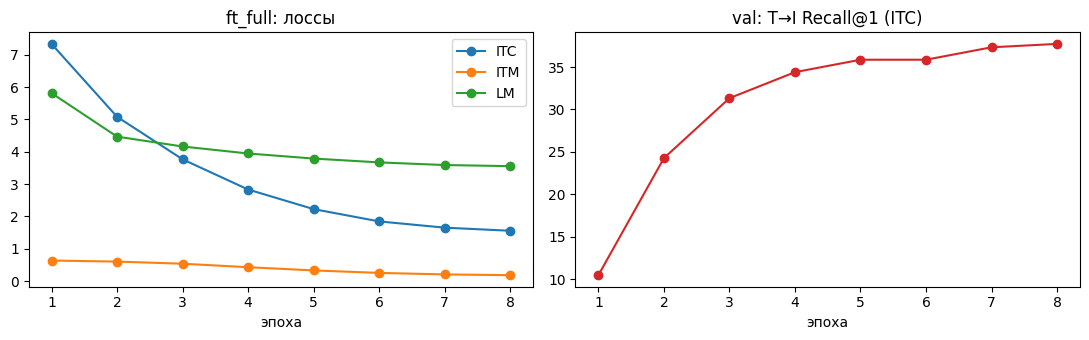

In [14]:
# ===================== ЭКСПЕРИМЕНТ 1: модель ДО и ПОСЛЕ обучения (ITC + ITM + LM) =====================
import matplotlib.pyplot as plt
from IPython.display import display

ensure_init()
LABEL_BEFORE = 'ДО: инициализация (ViT' + (' из DeiT' if PRETRAINED_VIT else '') + ', остальное случайно)'
LABEL_AFTER = 'ПОСЛЕ: обучение на Flickr30k (ITC+ITM+LM)'

m = load_model('init')
evaluate_all(m, 'init')
del m; free()

main_items = items_all_captions(train_imgs)
model_ft, hist_ft = train_or_load('ft_full', main_items, EPOCHS_MAIN, val=val_imgs)
evaluate_all(model_ft, 'ft_full')

tbl_main = results_table(['init', 'ft_full'], [LABEL_BEFORE, LABEL_AFTER])
display(tbl_main)
tbl_main.to_csv(f'{RES_DIR}/{MODEL}_table_main.csv')

def plot_history(hist, title):
    if not hist:
        print('нет истории обучения'); return
    ep = [h['epoch'] for h in hist]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for k, lab in (('loss_itc', 'ITC'), ('loss_itm', 'ITM'), ('loss_lm', 'LM')):
        ax[0].plot(ep, [h[k] for h in hist], marker='o', label=lab)
    ax[0].set_title(f'{title}: лоссы'); ax[0].set_xlabel('эпоха'); ax[0].legend()
    if 'val_t2i_R@1' in hist[0]:
        ax[1].plot(ep, [h['val_t2i_R@1'] for h in hist], marker='o', color='C3')
        ax[1].set_title('val: T→I Recall@1 (ITC)'); ax[1].set_xlabel('эпоха')
    plt.tight_layout(); plt.show()
plot_history(hist_ft, 'ft_full')

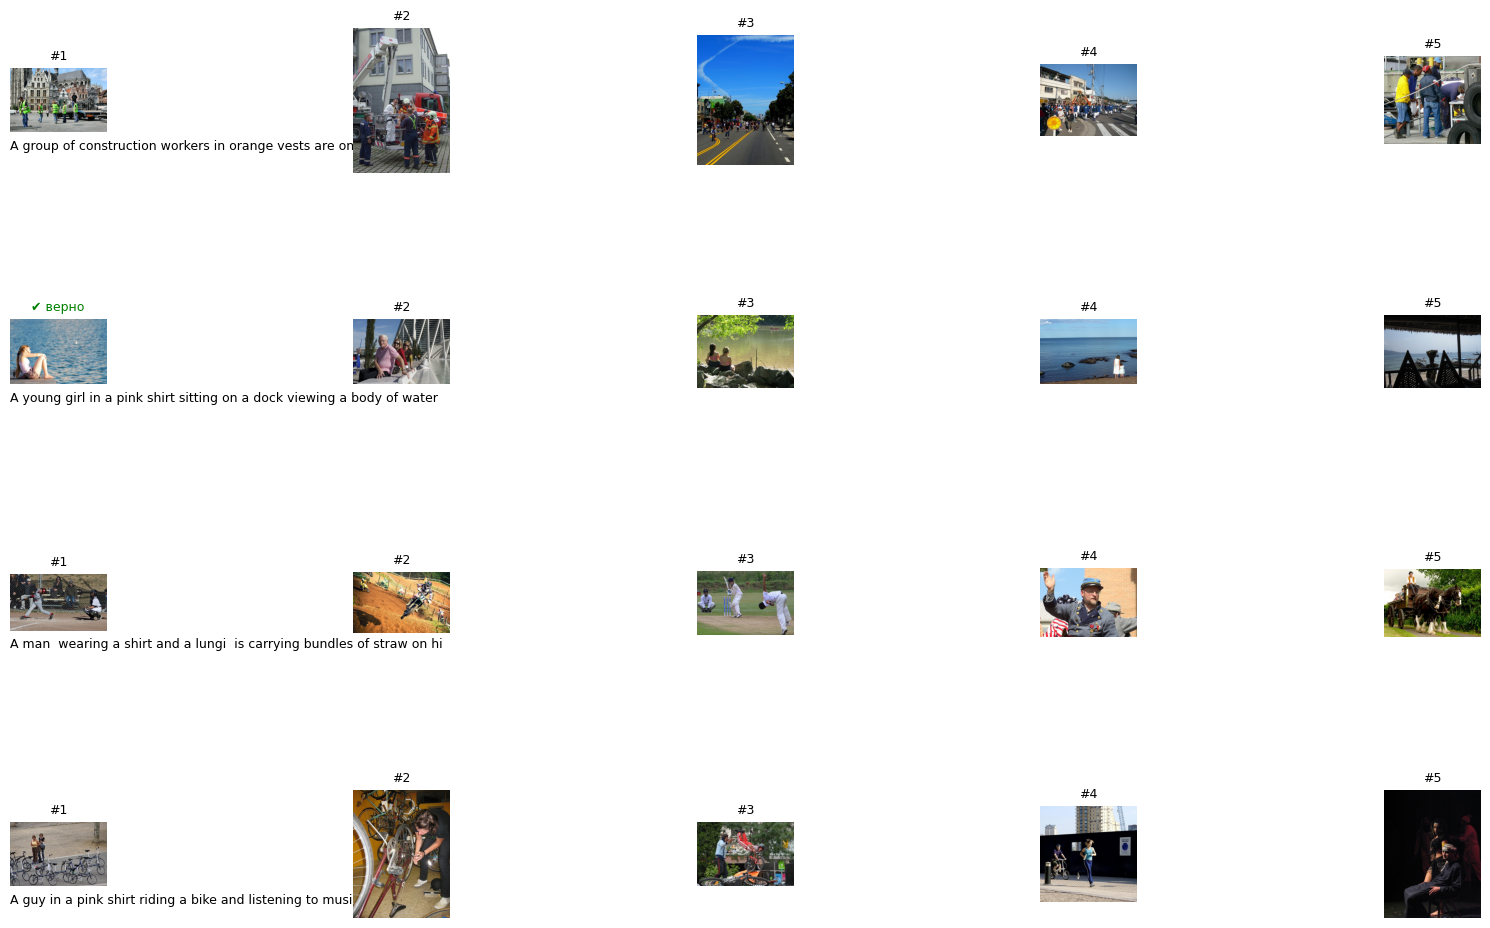

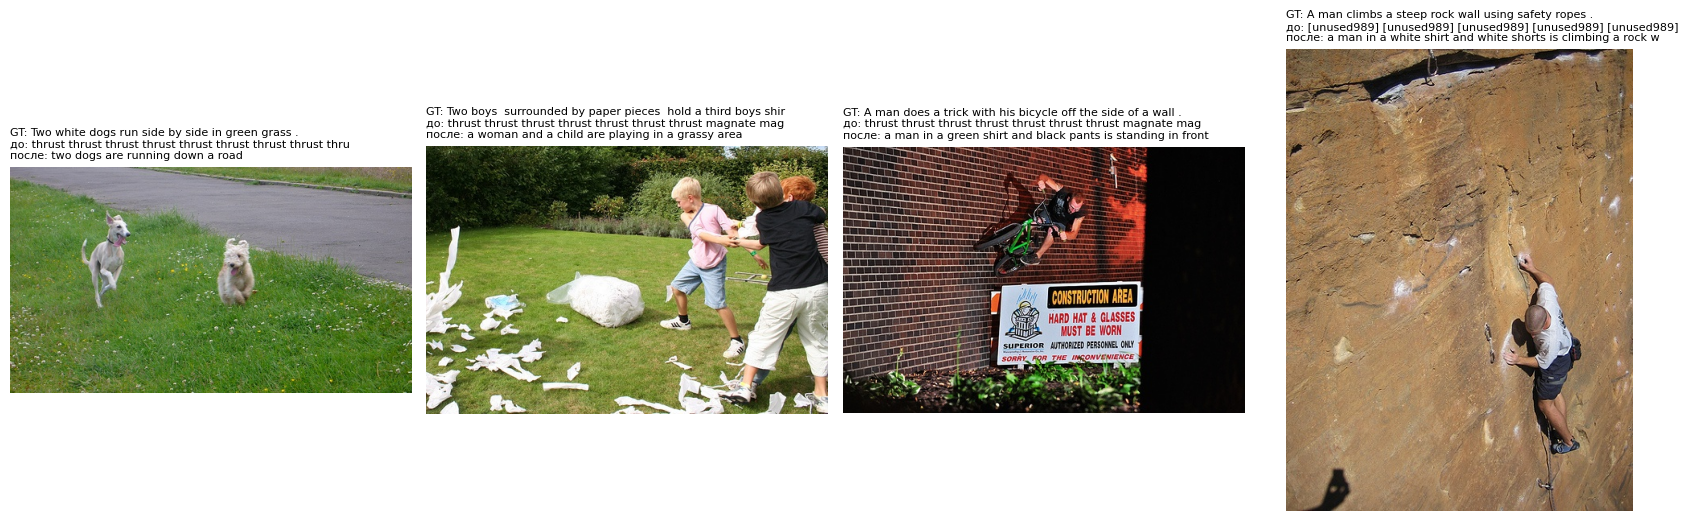

In [15]:
# ----- качественные примеры: поиск по тексту и подписи «до/после» -----
def show_retrieval(model, n_queries=4, topk=5, seed=1):
    files = [d['file'] for d in test_imgs]
    _, img_feat = image_features(model, files)
    rng = random.Random(seed)
    qs = [(i, rng.choice(test_imgs[i]['captions'])) for i in rng.sample(range(len(test_imgs)), n_queries)]
    fig, axes = plt.subplots(n_queries, topk, figsize=(3 * topk, 2.6 * n_queries))
    for r, (gi, q) in enumerate(qs):
        t = model.tokenize([pre_caption(q)], DEVICE)
        with torch.no_grad(), autocast():
            tf = model.text_cls(t.input_ids, t.attention_mask)
        top = (tf @ img_feat.t()).topk(topk, dim=1).indices[0].tolist()
        for c, j in enumerate(top):
            ax = axes[r, c]; ax.imshow(Image.open(f'{IMG_DIR}/{files[j]}')); ax.axis('off')
            ax.set_title('✔ верно' if j == gi else f'#{c + 1}', color='green' if j == gi else 'black', fontsize=9)
        axes[r, 0].text(0, -0.12, q[:70], transform=axes[r, 0].transAxes, fontsize=9, va='top')
    plt.tight_layout(); plt.show()

def show_captions(models, labels, n=4, seed=3):
    rng = random.Random(seed)
    idxs = rng.sample(range(len(test_imgs)), n)
    files = [test_imgs[i]['file'] for i in idxs]
    outs = [generate_captions(m, files, mode='beam', num_beams=3) for m in models]
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 5.2))
    for c, i in enumerate(idxs):
        axes[c].imshow(Image.open(f'{IMG_DIR}/{files[c]}')); axes[c].axis('off')
        txt = 'GT: ' + test_imgs[i]['captions'][0][:60] + '\n' + '\n'.join(f'{l}: {o[c][:60]}' for l, o in zip(labels, outs))
        axes[c].set_title(txt, fontsize=8, loc='left')
    plt.tight_layout(); plt.show()

show_retrieval(model_ft)
m0 = load_model('init')
show_captions([m0, model_ft], ['до', 'после'])
del m0; free()
del model_ft; free()          # дальше модели загружаются с Drive по необходимости

## 6. Эксперимент 2: CapFilt

**Идея статьи:** веб-пары (картинка, alt-text) шумные. Берём модель, дообучаем её на небольшом чистом наборе двумя способами: **captioner** (LM-лосс) генерирует синтетические подписи, **filter** (ITC/ITM) выбрасывает несоответствующие пары - и среди оригинальных веб-текстов, и среди синтетических. На очищенном наборе модель обучается заново.

**Как это имитируем:** изображения train делятся на *human* (`N_HUMAN` картинок × 5 подписей) и *web* (остальные, **одна** подпись, из них `NOISE_RATE` подменены подписью другой картинки). Так известно, какие подписи шумные, и можно измерить качество фильтра напрямую (ROC-AUC, точность/полнота по порогу τ).

Сравниваемые варианты (все обучаются с нуля из `init`, одинаковое число эпох):

| имя | данные |
|---|---|
| `cf_base` | human + web(шум) - без CapFilt |
| `cf_filter_only` | human + web, прошедшие фильтр |
| `cf_caption_only` | human + web + синтетические подписи (без фильтра) |
| `cf_full` | human + фильтр(web) + фильтр(синтетические) - полный CapFilt |
| `cf_oracle` | human + web с чистыми подписями - верхняя граница |

Captioner и filter получаются из `cf_base` дообучением на human-данных (как в статье - из предобученной модели; captioner только LM, filter - ITC+ITM).

human: 5000 пар (1000 изобр.) | web: 4000 пар, шума 1600 (40%)
пример шумной пары: A police officer standing next to a crowd of people in sailor suits .
[cf_base] обучение: 9000 пар, 5 эпох, веса лоссов (ITC,ITM,LM)=(1.0, 1.0, 1.0), старт из "init"


cf_base ep1/5:   0%|          | 0/140 [00:00<?, ?it/s]

[cf_base] ep 1/5: ITC 7.807 | ITM 0.659 | LM 6.917 | val t2i R@1 0.5 | 116 c


cf_base ep2/5:   0%|          | 0/140 [00:00<?, ?it/s]

[cf_base] ep 2/5: ITC 7.990 | ITM 0.625 | LM 5.147 | val t2i R@1 2.3 | 82 c


cf_base ep3/5:   0%|          | 0/140 [00:00<?, ?it/s]

... (14 outputs left out)

[cf_filter] ep 2/3: ITC 4.593 | ITM 0.554 | LM 0.000 | 53 c


cf_filter ep3/3:   0%|          | 0/78 [00:00<?, ?it/s]

[cf_filter] ep 3/3: ITC 4.006 | ITM 0.494 | LM 0.000 | 53 c
[cf_filter] чекпоинт сохранён: /content/drive/MyDrive/blip_mini/checkpoints/small_cf_filter.pth (196 МБ)
[cf_filter] оценка заняла 43 c
пример синтетической подписи: a person holding a hat
ROC-AUC детекции шумных подписей по ITM: 0.864


,"оставлено web, %","точность (оставленные чистые), %","доля шума, удалённого фильтром, %","чистых подписей потеряно, %","оставлено синтетических, %"
τ,,,,,
0.1,63.8,81.4,70.4,13.4,56.8
0.3,41.6,89.1,88.7,38.3,28.4
0.5,21.5,91.5,95.4,67.2,11.6
0.7,5.4,92.6,99.0,91.7,2.1
0.9,0.0,100.0,100.0,100.0,0.0


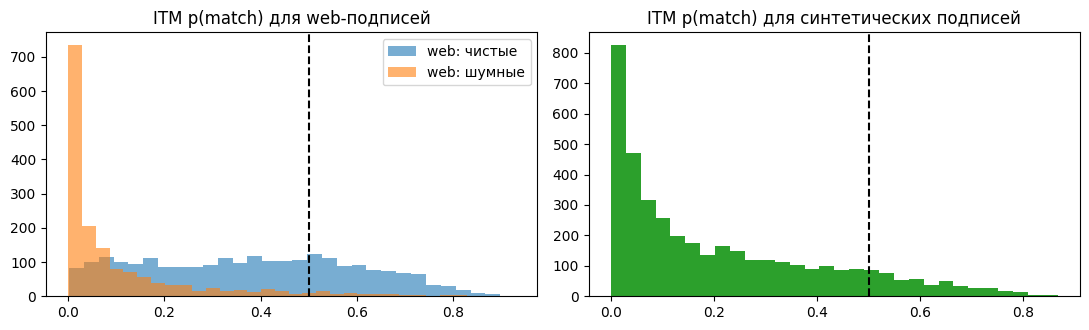

качество синтетических подписей относительно 5 эталонов (web-изображения): BLEU-4 4.2, CIDEr 7.1


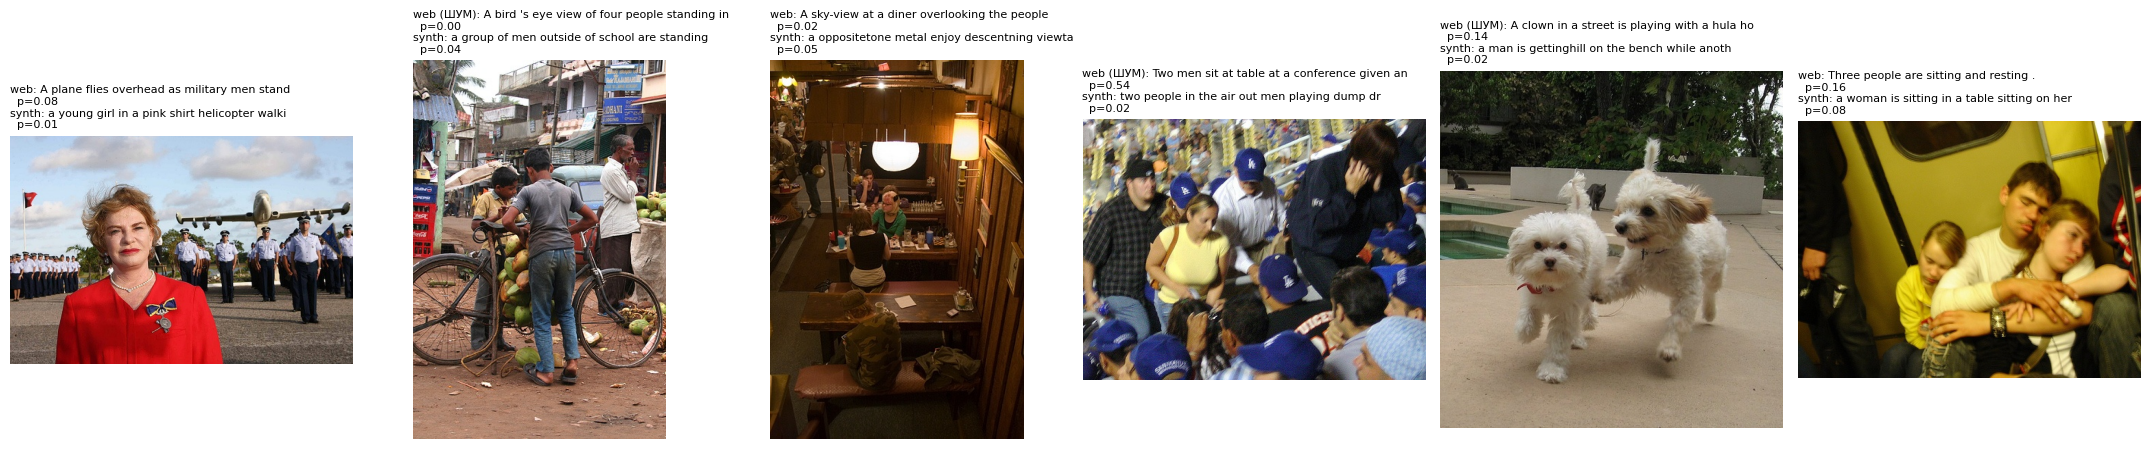

[cf_filter_only] обучение: 5861 пар, 5 эпох, веса лоссов (ITC,ITM,LM)=(1.0, 1.0, 1.0), старт из "init"


cf_filter_only ep1/5:   0%|          | 0/91 [00:00<?, ?it/s]

[cf_filter_only] ep 1/5: ITC 8.000 | ITM 0.674 | LM 7.295 | val t2i R@1 0.3 | 67 c


cf_filter_only ep2/5:   0%|          | 0/91 [00:00<?, ?it/s]

[cf_filter_only] ep 2/5: ITC 8.215 | ITM 0.630 | LM 5.375 | val t2i R@1 2.7 | 68 c


cf_filter_only ep3/5:   0%|          | 0/91 [00:00<?, ?it/s]

... (32 outputs left out)

[cf_oracle] ep 4/5: ITC 5.841 | ITM 0.589 | LM 4.429 | val t2i R@1 18.5 | 100 c


cf_oracle ep5/5:   0%|          | 0/140 [00:00<?, ?it/s]

[cf_oracle] ep 5/5: ITC 4.942 | ITM 0.554 | LM 4.324 | val t2i R@1 21.3 | 102 c
[cf_oracle] чекпоинт сохранён: /content/drive/MyDrive/blip_mini/checkpoints/small_cf_oracle.pth (196 МБ)
[cf_oracle] оценка заняла 49 c


,пар в обучении,T→I R@1,T→I R@5,T→I R@10,I→T R@1,I→T R@5,I→T R@10,T→I R@1 (ITC),BLEU-4,CIDEr
модель,,,,,,,,,,
без CapFilt: human + web(шум),9000,3.50,14.94,24.64,6.0,19.7,29.1,4.66,17.12,23.65
только фильтр: human + отфильтр. web,5861,4.00,16.00,26.78,4.8,17.9,28.0,5.46,15.16,22.65
только captioner: human + web + synth,13000,4.42,17.82,28.34,6.7,24.5,35.4,5.76,17.57,26.19
CapFilt: human + фильтр(web) + фильтр(synth),6325,3.96,16.56,28.44,4.1,18.6,28.9,6.44,15.68,23.48
верхняя граница: human + чистые web,9000,6.00,23.04,36.46,8.0,29.3,42.4,8.92,17.89,27.45


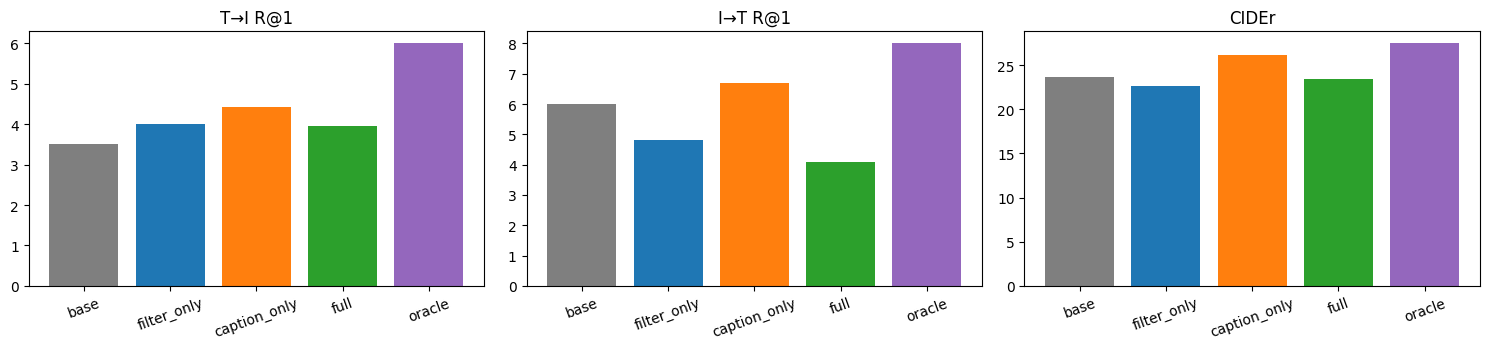

In [16]:
# ===================== ЭКСПЕРИМЕНТ 2: CapFilt (Captioning + Filtering) =====================
# Имитируем «веб-данные»: для train-изображений вне N_HUMAN берём ОДНУ подпись, причём NOISE_RATE из них подменены
# подписью другой картинки (известный шум => можно честно измерить качество фильтра).
# «Человеческие» данные: первые N_HUMAN изображений с 5 подписями.
#   1) baseline:   обучаем на human + web(шум)                                  -> cf_base
#   2) captioner:  cf_base дообучаем на human только с LM-лоссом                -> cf_captioner
#      filter:     cf_base дообучаем на human с ITC+ITM                         -> cf_filter
#   3) captioner генерирует синтетическую подпись каждому web-изображению (nucleus sampling, p=0.9);
#      filter оставляет пары (картинка, подпись) с p(ITM=match) > TAU - и для web-, и для синтетических подписей
#   4) заново (из init!) обучаем модели на очищенных/расширенных наборах и сравниваем на test.
rng = random.Random(SEED)
human_imgs, web_imgs = train_imgs[:N_HUMAN], train_imgs[N_HUMAN:]
items_h = items_all_captions(human_imgs)
noisy_ids = set(rng.sample(range(len(web_imgs)), int(NOISE_RATE * len(web_imgs))))
web_clean, web_noisy = [], []
for i, d in enumerate(web_imgs):
    base = {'file': d['file'], 'idx': FILE2IDX[d['file']]}
    cap = rng.choice(d['captions'])
    web_clean.append({**base, 'caption': cap, 'noisy': False})
    if i in noisy_ids:
        j = rng.randrange(len(web_imgs) - 1); j += (j >= i)            # другая картинка
        web_noisy.append({**base, 'caption': rng.choice(web_imgs[j]['captions']), 'noisy': True})
    else:
        web_noisy.append({**base, 'caption': cap, 'noisy': False})
print(f'human: {len(items_h)} пар ({len(human_imgs)} изобр.) | web: {len(web_noisy)} пар, шума {len(noisy_ids)} ({NOISE_RATE:.0%})')
print('пример шумной пары:', next((it['caption'] for it in web_noisy if it['noisy']), None))

# ---- 1) baseline ----
m, _ = train_or_load('cf_base', items_h + web_noisy, EPOCHS_CAPFILT, val=val_imgs)
evaluate_all(m, 'cf_base'); del m; free()

# ---- 2) captioner и filter: дообучение на человеческих данных ----
captioner, _ = train_or_load('cf_captioner', items_h, EPOCHS_FT_CF, init='cf_base', w=(0., 0., 1.), lr_scale=0.5)
evaluate_all(captioner, 'cf_captioner')
filt, _ = train_or_load('cf_filter', items_h, EPOCHS_FT_CF, init='cf_base', w=(1., 1., 0.), lr_scale=0.5)
evaluate_all(filt, 'cf_filter')

# ---- 3a) синтетические подписи (кэшируются на Drive) ----
SYN_PATH = f'{RES_DIR}/{MODEL}_cf_synthetic.json'
if os.path.exists(SYN_PATH) and not FORCE_RETRAIN:
    syn_caps = json.load(open(SYN_PATH))
else:
    set_seed(SEED)
    syn_caps = generate_captions(captioner, [d['file'] for d in web_imgs], mode='sample', top_p=0.9,
                                 max_length=30, min_length=5, repetition_penalty=1.1)
    json.dump(syn_caps, open(SYN_PATH, 'w'))
items_syn = [{'file': d['file'], 'idx': FILE2IDX[d['file']], 'caption': c, 'noisy': False}
             for d, c in zip(web_imgs, syn_caps) if norm_text(c)]
print('пример синтетической подписи:', items_syn[0]['caption'])

# ---- 3b) фильтр: ITM-вероятность соответствия ----
@torch.no_grad()
def itm_probs(model, items, bs=128):
    model.eval(); out = []
    for img, cap, _ in DataLoader(PairDS(items, test_tf), batch_size=bs, num_workers=NW):
        t = model.tokenize(list(cap), DEVICE)
        with autocast():
            lg = model.itm_logits(t.input_ids, t.attention_mask, model.visual_encoder(img.to(DEVICE)))
        out += F.softmax(lg, -1)[:, 1].tolist()
    return out

SC_PATH = f'{RES_DIR}/{MODEL}_cf_scores.json'
if os.path.exists(SC_PATH) and not FORCE_RETRAIN:
    sc = json.load(open(SC_PATH)); p_web, p_syn = sc['web'], sc['syn']
else:
    p_web, p_syn = itm_probs(filt, web_noisy), itm_probs(filt, items_syn)
    json.dump({'web': p_web, 'syn': p_syn}, open(SC_PATH, 'w'))
del captioner, filt; free()

# ---- 3c) анализ фильтра (по известным меткам шума) ----
from sklearn.metrics import roc_auc_score
y_noisy = np.array([it['noisy'] for it in web_noisy]); p_web_a, p_syn_a = np.array(p_web), np.array(p_syn)
print(f'ROC-AUC детекции шумных подписей по ITM: {roc_auc_score(y_noisy, 1 - p_web_a):.3f}')
rows = []
for tau in (0.1, 0.3, 0.5, 0.7, 0.9):
    keep = p_web_a > tau
    rows.append({'τ': tau, 'оставлено web, %': 100 * keep.mean(),
                 'точность (оставленные чистые), %': 100 * (~y_noisy[keep]).mean() if keep.any() else float('nan'),
                 'доля шума, удалённого фильтром, %': 100 * (~keep[y_noisy]).mean(),
                 'чистых подписей потеряно, %': 100 * (~keep[~y_noisy]).mean(),
                 'оставлено синтетических, %': 100 * (p_syn_a > tau).mean()})
display(pd.DataFrame(rows).set_index('τ').round(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(p_web_a[~y_noisy], bins=30, alpha=.6, label='web: чистые'); ax[0].hist(p_web_a[y_noisy], bins=30, alpha=.6, label='web: шумные')
ax[0].axvline(TAU, color='k', ls='--'); ax[0].set_title('ITM p(match) для web-подписей'); ax[0].legend()
ax[1].hist(p_syn_a, bins=30, color='C2'); ax[1].axvline(TAU, color='k', ls='--'); ax[1].set_title('ITM p(match) для синтетических подписей')
plt.tight_layout(); plt.show()

syn_m = caption_metrics([it['caption'] for it in items_syn], [d for d, c in zip(web_imgs, syn_caps) if norm_text(c)])
print('качество синтетических подписей относительно 5 эталонов (web-изображения): BLEU-4 %.1f, CIDEr %.1f' % (syn_m['BLEU-4'], syn_m['CIDEr']))

# примеры
def show_filter_examples(n=6, seed=5):
    r = random.Random(seed); ids = r.sample(range(len(web_imgs)), n)
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 4.6))
    sidx = {it['file']: k for k, it in enumerate(items_syn)}
    for c, i in enumerate(ids):
        d = web_noisy[i]; axes[c].imshow(Image.open(f"{IMG_DIR}/{d['file']}")); axes[c].axis('off')
        k = sidx.get(d['file'])
        t = f"web{' (ШУМ)' if d['noisy'] else ''}: {d['caption'][:45]}\n  p={p_web[i]:.2f}"
        if k is not None:
            t += f"\nsynth: {items_syn[k]['caption'][:45]}\n  p={p_syn[k]:.2f}"
        axes[c].set_title(t, fontsize=8, loc='left')
    plt.tight_layout(); plt.show()
show_filter_examples()

# ---- 4) варианты обучающих наборов; каждый учится с нуля (из init) ----
keep_web = [it for it, p in zip(web_noisy, p_web) if p > TAU]
keep_syn = [it for it, p in zip(items_syn, p_syn) if p > TAU]
variants = {
    'cf_base':    ('без CapFilt: human + web(шум)', None),
    'cf_filter_only':  ('только фильтр: human + отфильтр. web', items_h + keep_web),
    'cf_caption_only': ('только captioner: human + web + synth', items_h + web_noisy + items_syn),
    'cf_full':    ('CapFilt: human + фильтр(web) + фильтр(synth)', items_h + keep_web + keep_syn),
    'cf_oracle':  ('верхняя граница: human + чистые web', items_h + web_clean),
}
for name, (_, its) in variants.items():
    if its is None:
        continue
    m, _ = train_or_load(name, its, EPOCHS_CAPFILT, val=val_imgs)
    evaluate_all(m, name); del m; free()

names = list(variants)
tbl_cf = results_table(names, [variants[n][0] for n in names])
n_pairs = {'cf_base': len(items_h) + len(web_noisy)}
for n, (_, its) in variants.items():
    if its is not None: n_pairs[n] = len(its)
tbl_cf.insert(0, 'пар в обучении', [n_pairs[n] for n in names])
display(tbl_cf)
tbl_cf.to_csv(f'{RES_DIR}/{MODEL}_table_capfilt.csv')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, col in zip(ax, ['T→I R@1', 'I→T R@1', 'CIDEr']):
    a.bar(range(len(names)), tbl_cf[col].values, color=['C7', 'C0', 'C1', 'C2', 'C4'])
    a.set_xticks(range(len(names))); a.set_xticklabels([n.replace('cf_', '') for n in names], rotation=20); a.set_title(col)
plt.tight_layout(); plt.show()

## 7. Эксперимент 3: стратегии генерации

Одна и та же модель (`ft_full`), разные декодирования: **greedy**, **beam search** (3 и 5 лучей), **nucleus (top-p) sampling**, p = 0.5 / 0.9 / 1.0 (чистое сэмплирование). Помимо BLEU-4/CIDEr считаем разнообразие: долю уникальных подписей и distinct-1/2. Ожидаемо: beam даёт максимум метрик, но однообразные подписи; nucleus - менее точные по метрикам, зато разнообразные (именно поэтому в CapFilt для синтетических подписей берут nucleus sampling).

greedy: CIDEr 38.3, 14 c
beam-3: CIDEr 41.3, 17 c
beam-5: CIDEr 41.1, 25 c
nucleus p=0.5: CIDEr 29.3, 14 c
nucleus p=0.9: CIDEr 14.9, 15 c
sampling p=1.0: CIDEr 9.2, 15 c


,BLEU-4,CIDEr,avg_len,distinct_captions,distinct-1,distinct-2,сек
greedy,19.782,38.268,12.300,0.955,0.030,0.100,14
beam-3,21.693,41.311,12.214,0.907,0.030,0.086,17
beam-5,21.776,41.141,12.056,0.891,0.029,0.083,25
nucleus p=0.5,15.684,29.330,12.638,0.997,0.052,0.197,14
nucleus p=0.9,7.338,14.911,12.619,1.000,0.143,0.493,15
sampling p=1.0,5.184,9.203,11.763,1.000,0.258,0.647,15


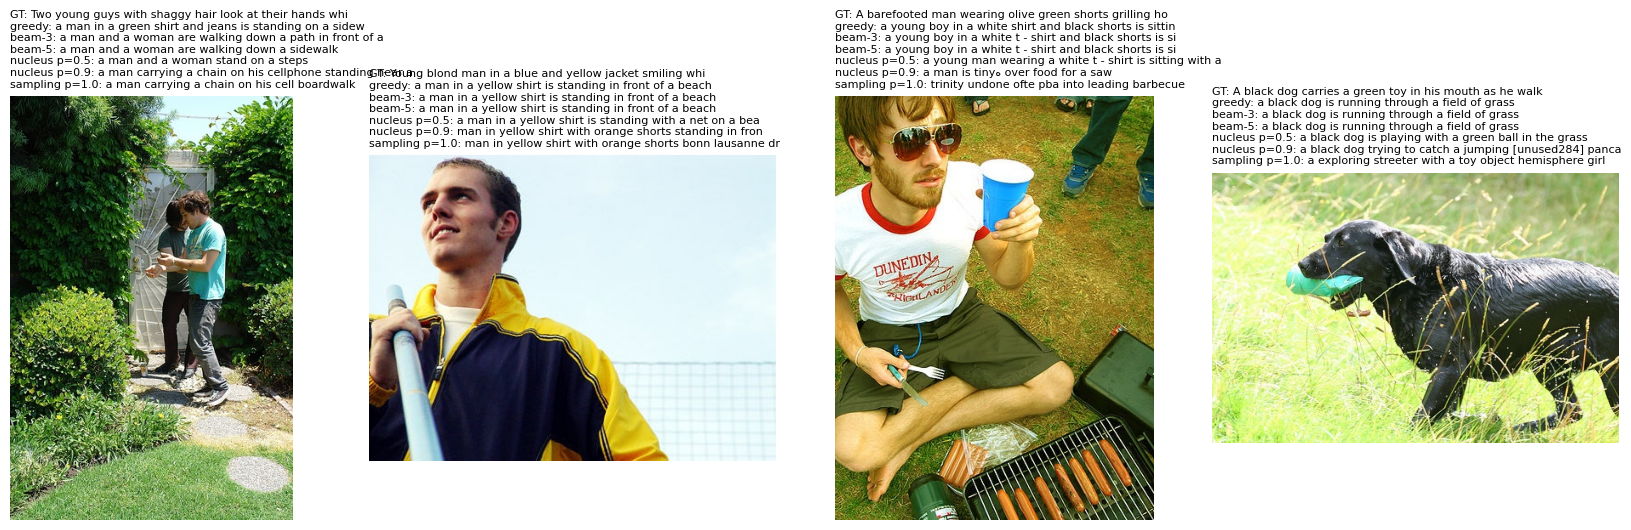

In [17]:
# ===================== ЭКСПЕРИМЕНТ 3: стратегии генерации подписей =====================
GEN_PATH = f'{RES_DIR}/{MODEL}_gen_study.json'
strategies = {
    'greedy':           dict(mode='greedy'),
    'beam-3':           dict(mode='beam', num_beams=3),
    'beam-5':           dict(mode='beam', num_beams=5),
    'nucleus p=0.5':    dict(mode='sample', top_p=0.5),
    'nucleus p=0.9':    dict(mode='sample', top_p=0.9),
    'sampling p=1.0':   dict(mode='sample', top_p=1.0),
}
test_files = [d['file'] for d in test_imgs]
if os.path.exists(GEN_PATH) and not FORCE_RETRAIN:
    gen = json.load(open(GEN_PATH))
else:
    mg = load_model('ft_full'); gen = {}
    for name, kw in strategies.items():
        set_seed(SEED); t0 = time.time()
        hyps = generate_captions(mg, test_files, max_length=30, min_length=5, **kw)
        gen[name] = {'metrics': caption_metrics(hyps, test_imgs), 'hyps': hyps[:50], 'sec': time.time() - t0}
        print(f'{name}: CIDEr {gen[name]["metrics"]["CIDEr"]:.1f}, {gen[name]["sec"]:.0f} c')
    json.dump(gen, open(GEN_PATH, 'w'), indent=1); del mg; free()

tbl_gen = pd.DataFrame({k: v['metrics'] for k, v in gen.items()}).T[['BLEU-4', 'CIDEr', 'avg_len', 'distinct_captions', 'distinct-1', 'distinct-2']].round(3)
tbl_gen['сек'] = [round(gen[k]['sec']) for k in tbl_gen.index]
display(tbl_gen); tbl_gen.to_csv(f'{RES_DIR}/{MODEL}_table_generation.csv')

# примеры: одни и те же картинки, разные стратегии
fig, axes = plt.subplots(1, 4, figsize=(17, 5.4))
for c in range(4):
    axes[c].imshow(Image.open(f'{IMG_DIR}/{test_files[c]}')); axes[c].axis('off')
    axes[c].set_title('GT: ' + test_imgs[c]['captions'][0][:55] + '\n' + '\n'.join(f'{k}: {gen[k]["hyps"][c][:55]}' for k in strategies),
                      fontsize=8, loc='left')
plt.tight_layout(); plt.show()

## 8. Итоги и что сохранено

In [18]:
# ===================== ИТОГИ =====================
print('Основной эксперимент:'); display(tbl_main)
print('CapFilt:'); display(tbl_cf)
print('Стратегии генерации:'); display(tbl_gen)
print('\nСохранено на Drive:')
for d in (CKPT_DIR, RES_DIR):
    for f in sorted(os.listdir(d)):
        print(f'  {d}/{f}  ({os.path.getsize(os.path.join(d, f)) / 2**20:.1f} МБ)')

Основной эксперимент:


,T→I R@1,T→I R@5,T→I R@10,I→T R@1,I→T R@5,I→T R@10,T→I R@1 (ITC),BLEU-4,CIDEr
модель,,,,,,,,,
"ДО: инициализация (ViT из DeiT, остальное случайно)",0.1,0.50,1.08,0.0,0.4,1.0,0.14,0.00,0.00
ПОСЛЕ: обучение на Flickr30k (ITC+ITM+LM),18.4,42.56,55.12,21.0,49.5,63.5,19.68,21.69,41.31


CapFilt:


,пар в обучении,T→I R@1,T→I R@5,T→I R@10,I→T R@1,I→T R@5,I→T R@10,T→I R@1 (ITC),BLEU-4,CIDEr
модель,,,,,,,,,,
без CapFilt: human + web(шум),9000,3.50,14.94,24.64,6.0,19.7,29.1,4.66,17.12,23.65
только фильтр: human + отфильтр. web,5861,4.00,16.00,26.78,4.8,17.9,28.0,5.46,15.16,22.65
только captioner: human + web + synth,13000,4.42,17.82,28.34,6.7,24.5,35.4,5.76,17.57,26.19
CapFilt: human + фильтр(web) + фильтр(synth),6325,3.96,16.56,28.44,4.1,18.6,28.9,6.44,15.68,23.48
верхняя граница: human + чистые web,9000,6.00,23.04,36.46,8.0,29.3,42.4,8.92,17.89,27.45


Стратегии генерации:


,BLEU-4,CIDEr,avg_len,distinct_captions,distinct-1,distinct-2,сек
greedy,19.782,38.268,12.300,0.955,0.030,0.100,14
beam-3,21.693,41.311,12.214,0.907,0.030,0.086,17
beam-5,21.776,41.141,12.056,0.891,0.029,0.083,25
nucleus p=0.5,15.684,29.330,12.638,0.997,0.052,0.197,14
nucleus p=0.9,7.338,14.911,12.619,1.000,0.143,0.493,15
sampling p=1.0,5.184,9.203,11.763,1.000,0.258,0.647,15



Сохранено на Drive:
  /content/drive/MyDrive/blip_mini/checkpoints/small_cf_base.pth  (196.2 МБ)
  /content/drive/MyDrive/blip_mini/checkpoints/small_cf_caption_only.pth  (196.2 МБ)
  /content/drive/MyDrive/blip_mini/checkpoints/small_cf_captioner.pth  (196.2 МБ)
  /content/drive/MyDrive/blip_mini/checkpoints/small_cf_filter.pth  (196.2 МБ)
  /content/drive/MyDrive/blip_mini/checkpoints/small_cf_filter_only.pth  (196.2 МБ)
  /content/drive/MyDrive/blip_mini/checkpoints/small_cf_full.pth  (196.2 МБ)
  /content/drive/MyDrive/blip_mini/checkpoints/small_cf_oracle.pth  (196.2 МБ)
  /content/drive/MyDrive/blip_mini/checkpoints/small_ft_full.pth  (196.2 МБ)
  /content/drive/MyDrive/blip_mini/checkpoints/small_init.pth  (196.2 МБ)
  /content/drive/MyDrive/blip_mini/results/small_cf_base.json  (0.0 МБ)
  /content/drive/MyDrive/blip_mini/results/small_cf_base_trainlog.json  (0.0 МБ)
  /content/drive/MyDrive/blip_mini/results/small_cf_caption_only.json  (0.0 МБ)
  /content/drive/MyDrive/blip_mi

## Замечания по интерпретации

* **BLEU/CIDEr** считаются реализациями из `pycocoevalcap` (`Bleu`, `Cider`) с простой токенизацией (нижний регистр, только `[a-z0-9']`), без Java-PTBTokenizer и без METEOR/SPICE. Тренд между моделями корректен, но абсолютные числа нельзя напрямую сравнивать со значениями из статей.
* Модель и данные маленькие (по умолчанию 5000 изображений), один сид - различия в 1-2 пункта между вариантами CapFilt могут быть в пределах шума. Для более надёжных выводов увеличьте `N_TRAIN` / число эпох или повторите с другим `SEED`.
* От оригинального CapFilt отличается масштаб и способ получения «веба» (имитация шума подменой подписей), а captioner/filter стартуют из `cf_base`, а не из модели, предобученной на 129M пар; ViT-инициализация (DeiT) - единственное внешнее предобучение.
* Текстовая часть учится с нуля на малых данных, поэтому абсолютные метрики скромные; главное - сравнение между вариантами. ITC учитывает id изображений (как в `blip_retrieval.py`).